# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

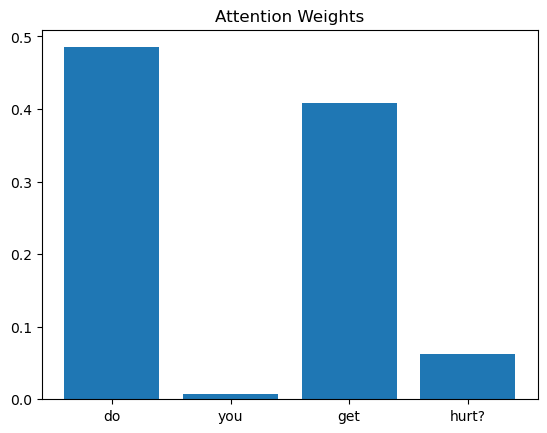

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 1: do you get hurt?
Highest attention: 'do' (weight = 0.4851)

Question 2: do you have fingers?
Highest attention: 'do' (weight = 0.8270)

Question 3: do you ever breathe
Highest attention: 'do' (weight = 0.6996)



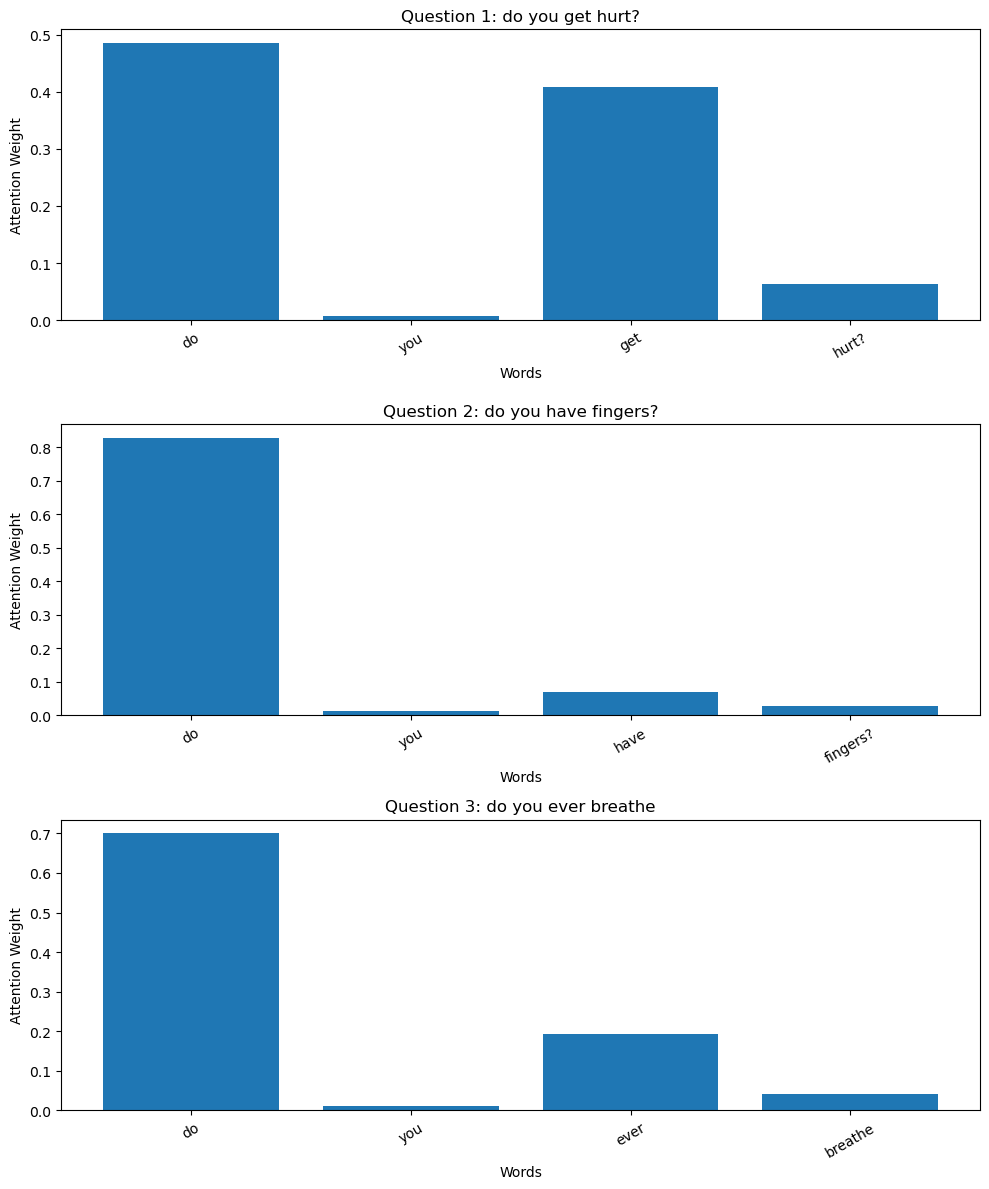

In [7]:
# Select three questions from the dataset
selected_indices = [0, 1, 2]

model.eval()

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for ax, idx in zip(axes, selected_indices):
    question = df.iloc[idx]["question"]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])

    question_weights = weights[0, :len(words)].cpu().numpy()

    highest_idx = question_weights.argmax()
    highest_word = words[highest_idx]
    highest_weight = question_weights[highest_idx]

    ax.bar(words, question_weights)
    ax.set_title(f"Question {idx + 1}: {question}")
    ax.set_xlabel("Words")
    ax.set_ylabel("Attention Weight")
    ax.tick_params(axis="x", rotation=30)

    print(
        f"Question {idx + 1}: {question}\n"
        f"Highest attention: '{highest_word}' "
        f"(weight = {highest_weight:.4f})\n"
    )

plt.tight_layout()
plt.show()

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

The words with the highest attention weights generally appear important because they often contain meaningful information about the question. For example, keywords can help the model identify the topic or intention of the question. This suggests that attention helps the model focus on relevant words. However, the highest attention weight does not always mean that a word is the most important for understanding the question

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Selected Questions:
Question 1: are you old?
Question 2: what's your birthday?
Answer Group: 1

Question 1: Highest attention word = 'are' (Weight = 0.6517)

Question 2: Highest attention word = 'what's' (Weight = 0.5594)


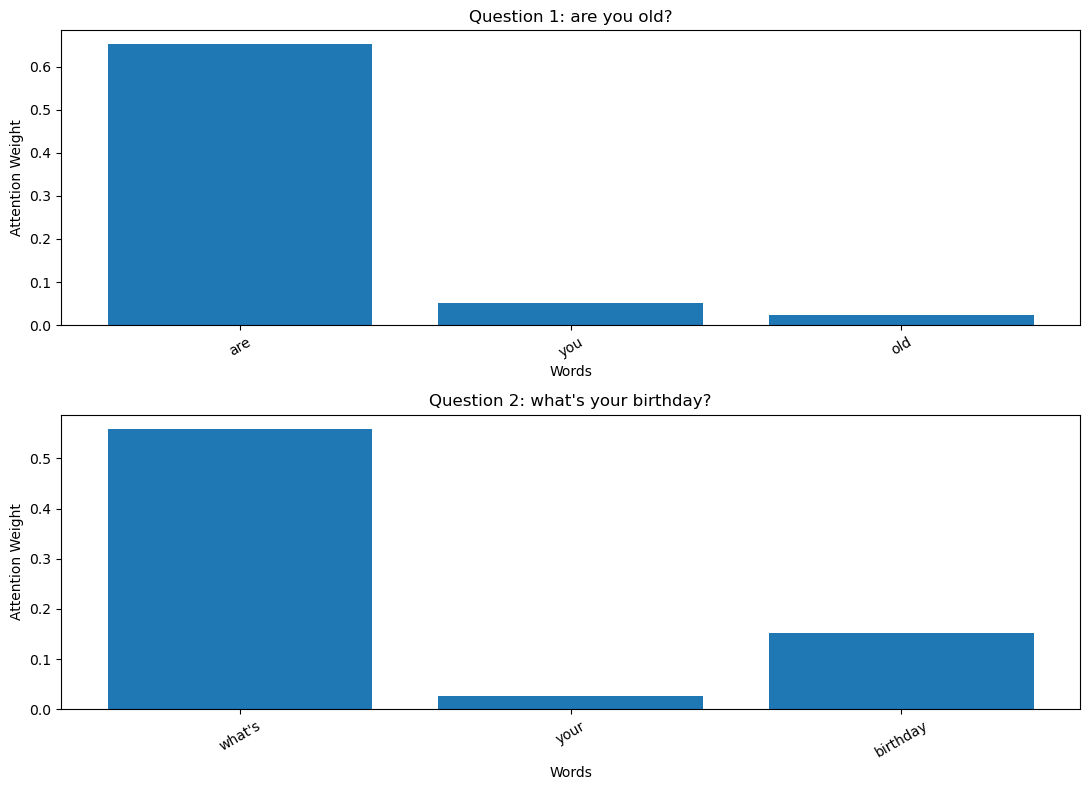

In [8]:
import itertools

# Select two questions with the same answer_id
# but different wording

def get_word_set(question):
    return set(tokenizer.texts_to_sequences([question])[0])

candidate_pairs = []

for answer_group, group in df.groupby("answer_id"):
    indices = group.index.tolist()

    for idx1, idx2 in itertools.combinations(indices, 2):
        q1 = str(df.loc[idx1, "question"])
        q2 = str(df.loc[idx2, "question"])

        if q1.strip() == q2.strip():
            continue

        words1 = get_word_set(q1)
        words2 = get_word_set(q2)

        if not words1 or not words2:
            continue

        similarity = len(words1 & words2) / len(words1 | words2)

        candidate_pairs.append(
            (similarity, answer_group, idx1, idx2)
        )

if not candidate_pairs:
    raise ValueError("No suitable pair of questions was found.")

# Select two questions with different wording
candidate_pairs.sort(key=lambda item: item[0])

similarity, answer_group, idx1, idx2 = candidate_pairs[0]

selected_indices = [idx1, idx2]

print("Selected Questions:")
print("Question 1:", df.loc[idx1, "question"])
print("Question 2:", df.loc[idx2, "question"])
print("Answer Group:", answer_group)


# Visualize attention weights
model.eval()

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

for question_number, (ax, idx) in enumerate(
    zip(axes, selected_indices), start=1
):

    sequence = tokenizer.texts_to_sequences(
        [df.loc[idx, "question"]]
    )[0]

    words = [
        tokenizer.index_word[token_id]
        for token_id in sequence
    ]

    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])

    question_weights = weights[0, :len(words)].cpu().numpy()

    # Find the word with the highest attention weight
    highest_idx = question_weights.argmax()
    highest_word = words[highest_idx]
    highest_weight = question_weights[highest_idx]

    # Plot attention weights
    ax.bar(words, question_weights)
    ax.set_title(
        f"Question {question_number}: {df.loc[idx, 'question']}"
    )
    ax.set_xlabel("Words")
    ax.set_ylabel("Attention Weight")
    ax.tick_params(axis="x", rotation=30)

    print(
        f"\nQuestion {question_number}: "
        f"Highest attention word = '{highest_word}' "
        f"(Weight = {highest_weight:.4f})"
    )

plt.tight_layout()
plt.show()

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

The model may focus on similar words when questions have similar meanings, especially when they share important keywords. However, it may also focus on different words because of differences in wording and sentence structure. This suggests that attention assigns weights based on the learned importance of words in each question. Therefore, similar questions can have similar attention patterns, but they do not have to be identical.